# Crypto pairs trading (AMA4370)

**Strategy in one sentence:** find two coins whose prices move together, and when the gap between them
(the *spread*) is unusually large, bet that it closes again: buy the cheap one, short the expensive one.

Steps of this notebook:
1. Data: hourly prices and funding rates of 12 Binance perpetual futures, 2023-01 to 2026-10
2. Pair selection: cointegration test of all 66 pairs (**train data only**)
3. Spread and z-score of the chosen pair
4. Calibration: choose the parameters (**train data only**)
5. Results on train (in-sample)
6. Results on test (out-of-sample, looked at **once**, nothing changed afterwards)
7. Challenges, 8. Conclusions

All code is in `src/data.py` (loading data) and `src/strategy.py` (everything else). All settings are in `config.yaml`.

In [16]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle
from src import data, strategy

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
cfg = data.load_config()

## 1. Data

Loaded 33600 hours x 12 coins, 0 missing prices
Train: 2023-01-01 to 2025-12-31 (26304 hours)
Test:  2026-01-01 to 2026-10-31 (7296 hours)


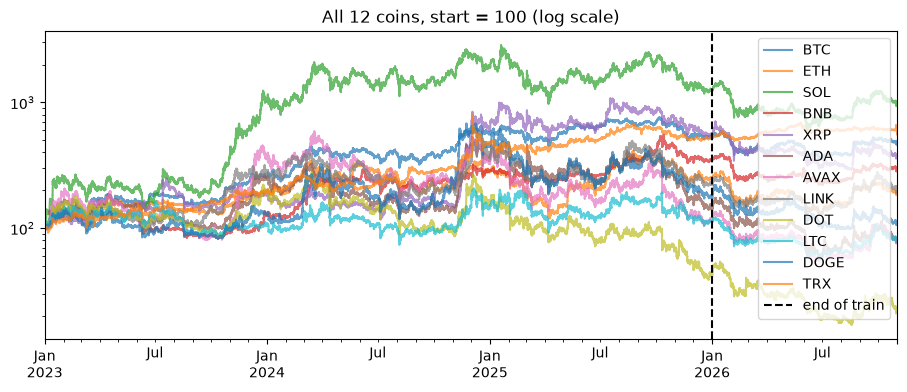

In [17]:
prices, funding = data.load_data(cfg)       # one column per coin, one row per hour
train_prices, test_prices = data.split(prices, cfg)
print(f"Train: {train_prices.index[0]:%Y-%m-%d} to {train_prices.index[-1]:%Y-%m-%d} ({len(train_prices)} hours)")
print(f"Test:  {test_prices.index[0]:%Y-%m-%d} to {test_prices.index[-1]:%Y-%m-%d} ({len(test_prices)} hours)")

(prices / prices.iloc[0] * 100).plot(logy=True, legend=False, alpha=0.7, title="All 12 coins, start = 100 (log scale)")
plt.axvline(pd.Timestamp(cfg["train_end"], tz="UTC"), color="k", ls="--", label="end of train")
plt.legend(); plt.show()

The data is complete: no missing hours for any coin. Funding is paid every 8 hours. A positive funding rate
means longs pay shorts. In a pair trade we are long one coin and short the other, so the two funding payments
mostly cancel out.

## 2. Pair selection (train data only)

For every pair we run the **Engle-Granger test**: regress log(A) on log(B), then test whether the residual
(= the spread) is stationary (ADF test). A low p-value means the spread tends to come back to its mean.

How to read the table:
- `p_bonferroni`: we test 66 pairs, so about 3 of them look significant at 5% by pure luck. Bonferroni multiplies the p-value by 66 to correct for this.
- `adf_p_a`, `adf_p_b`: is each coin **on its own** already stationary? It should not be (high p-value). If it is, the "pair" is fake.
- `half_life_h`: hours until the spread has closed half of its distance to the mean.

First a look at how the coins move together: correlation of hourly **log returns** on train data.
We use returns, not prices, because two trending price series look correlated even when they are unrelated.
High correlation is not the same as cointegration, but it is a useful first filter.

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

corr = np.log(train_prices).diff().dropna().corr()
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
n = len(corr)
fig, ax = plt.subplots(figsize=(0.65 * n + 2, 0.6 * n + 1))
im = ax.imshow(corr.to_numpy(), cmap=blues, vmin=corr.min().min(), vmax=1)
for i in range(n):
    for j in range(n):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.75 else "black")
ax.set_xticks(range(n), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(n), corr.index)
fig.colorbar(im, ax=ax, label="Correlation", shrink=0.8)
ax.set_title("Correlation of hourly log returns (train)")
plt.tight_layout(); plt.show()

All coins are strongly correlated (mostly 0.6–0.8) because they share one common crypto market factor.
BTC/ETH (0.81) and the altcoin cluster ADA, DOT, LINK, AVAX are the most correlated. TRX (about 0.45 with
everything) is the outlier. ETH/BNB, our final pair, has 0.71.

Now the cointegration test for every pair:

In [18]:
ranking = strategy.rank_pairs(train_prices)
ranking.head(10)

,a,b,correlation,p_value,p_bonferroni,beta,half_life_h,adf_p_a,adf_p_b
0,LTC,DOGE,0.668,0.014,0.906,0.242,601.171,0.010,0.459
1,LTC,TRX,0.461,0.028,1.000,0.158,650.097,0.010,0.638
2,BTC,TRX,0.454,0.106,1.000,0.953,1243.869,0.188,0.638
3,SOL,LINK,0.692,0.170,1.000,1.933,1223.831,0.132,0.211
4,ADA,LTC,0.702,0.224,1.000,1.458,1455.620,0.274,0.010
5,ADA,DOGE,0.721,0.225,1.000,0.679,1181.886,0.274,0.459
6,SOL,DOGE,0.659,0.273,1.000,1.459,2097.636,0.132,0.459
7,ETH,BNB,0.713,0.288,1.000,0.529,1762.213,0.151,0.766
8,XRP,TRX,0.455,0.289,1.000,1.238,1849.797,0.688,0.638
9,LINK,DOGE,0.702,0.292,1.000,0.656,1717.984,0.211,0.459


**What we see:**
- The two best pairs both contain **LTC**. But `adf_p` of LTC alone is about 0.01: LTC moved sideways in a range
  on its own, so these "pairs" are just LTC. We drop them.
- **No pair is significant after Bonferroni** (all `p_bonferroni` far above 0.05). Statistically, no pair is clearly cointegrated over the full train period.
- Half-lives are long (weeks), so we use a **rolling** hedge ratio and z-score that adapt over time.

So the test result alone does not give us a clear winner. We therefore choose the pair with the calibration in section 4:
we take a few liquid, economically related candidates and backtest them on train.
Our choice: **ETH / BNB**. Both are the native coins of the two biggest smart-contract platforms
(Ethereum and BNB Chain), their returns have a correlation of 0.71, and neither is stationary alone.

## 3. Spread and z-score of the chosen pair

- **beta** (hedge ratio): slope of log(ETH) on log(BNB) over the last `hedge_window` hours (rolling, past data only)
- **spread** = log(ETH) − beta · log(BNB) − alpha
- **z-score** = (spread − rolling mean) / rolling std, over the last `zscore_lookback` hours

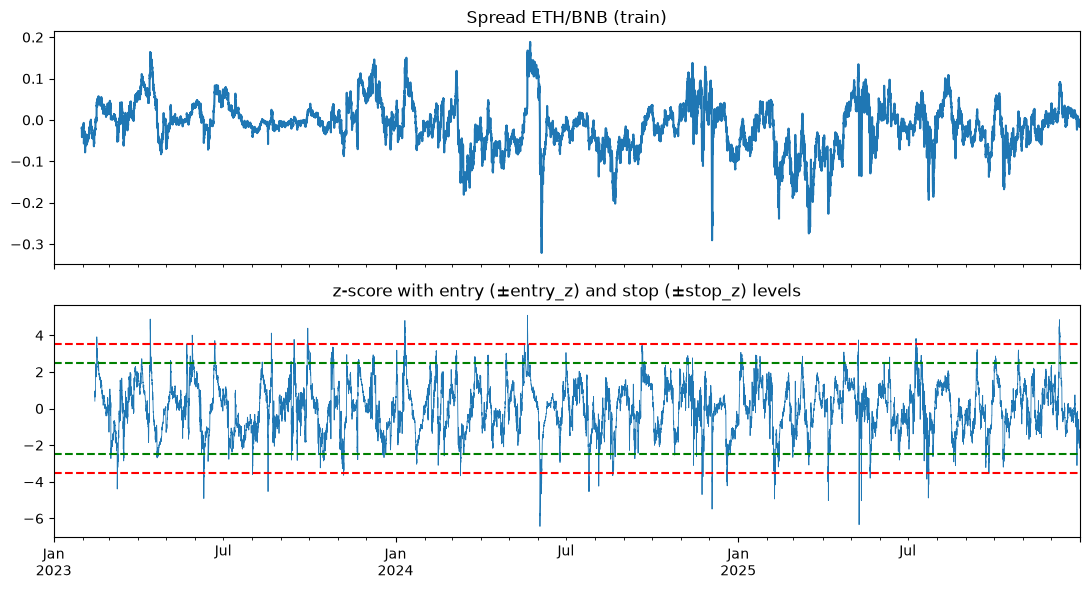

In [19]:
res_train = strategy.backtest(prices, funding, cfg, "train")
bars = res_train["bars"]
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
bars["spread"].plot(ax=ax[0], title=f"Spread {cfg['pair'][0]}/{cfg['pair'][1]} (train)")
bars["z"].plot(ax=ax[1], title="z-score with entry (±entry_z) and stop (±stop_z) levels", lw=0.6)
for level, color in [(cfg["entry_z"], "g"), (cfg["stop_z"], "r")]:
    ax[1].axhline(level, color=color, ls="--"); ax[1].axhline(-level, color=color, ls="--")
plt.tight_layout(); plt.show()

## 4. Calibration (train data only)

**Trading rules** (in `strategy.positions`):
- **Entry:** z < −entry_z → long the spread (buy ETH, short BNB). z > +entry_z → short the spread.
- **Take profit:** close when z is back at the mean (exit_z = 0).
- **Stop loss:** close when |z| > stop_z. The spread keeps running away, so maybe the relationship broke.
- **Time stop:** close after time_stop_hours. The spread is not coming back in a reasonable time.
- After a stop we wait until |z| < entry_z before trading again.

**Costs:** 0.05% fee + 0.02% slippage per leg and trade, so one round trip costs about 0.14% of capital.

### 4a. Pair and signal parameters
Sharpe ratio on train for a grid of candidate pairs × hedge window × z-score lookback × entry threshold.

In [20]:
candidates = [["ETH", "BTC"], ["ETH", "BNB"], ["SOL", "LINK"], ["BTC", "BNB"], ["ADA", "DOGE"], ["LINK", "DOGE"]]
rows = []
for pair, hw, lb, ez in itertools.product(candidates, [480, 720, 1080], [168, 336, 504], [2.0, 2.5, 3.0]):
    m = strategy.backtest(prices, funding, dict(cfg, pair=pair, hedge_window=hw, zscore_lookback=lb, entry_z=ez))["metrics"]
    rows.append({"pair": "/".join(pair), "hedge_window": hw, "lookback": lb, "entry_z": ez,
                 "sharpe": m["sharpe"], "max_drawdown": m["max_drawdown"], "n_trades": m["n_trades"]})
grid = pd.DataFrame(rows)

# Best cell of each pair, with its drawdown
grid.loc[grid.groupby("pair")["sharpe"].idxmax()].sort_values("sharpe", ascending=False).set_index("pair")

,hedge_window,lookback,entry_z,sharpe,max_drawdown,n_trades
pair,,,,,,
ADA/DOGE,1080,336,2.000,0.874,-0.264,123
ETH/BNB,720,336,2.500,0.824,-0.170,101
SOL/LINK,720,336,2.000,0.508,-0.281,119
LINK/DOGE,480,336,2.500,0.361,-0.338,110
ETH/BTC,1080,336,3.000,0.296,-0.153,66
BTC/BNB,480,504,3.000,-0.132,-0.244,45


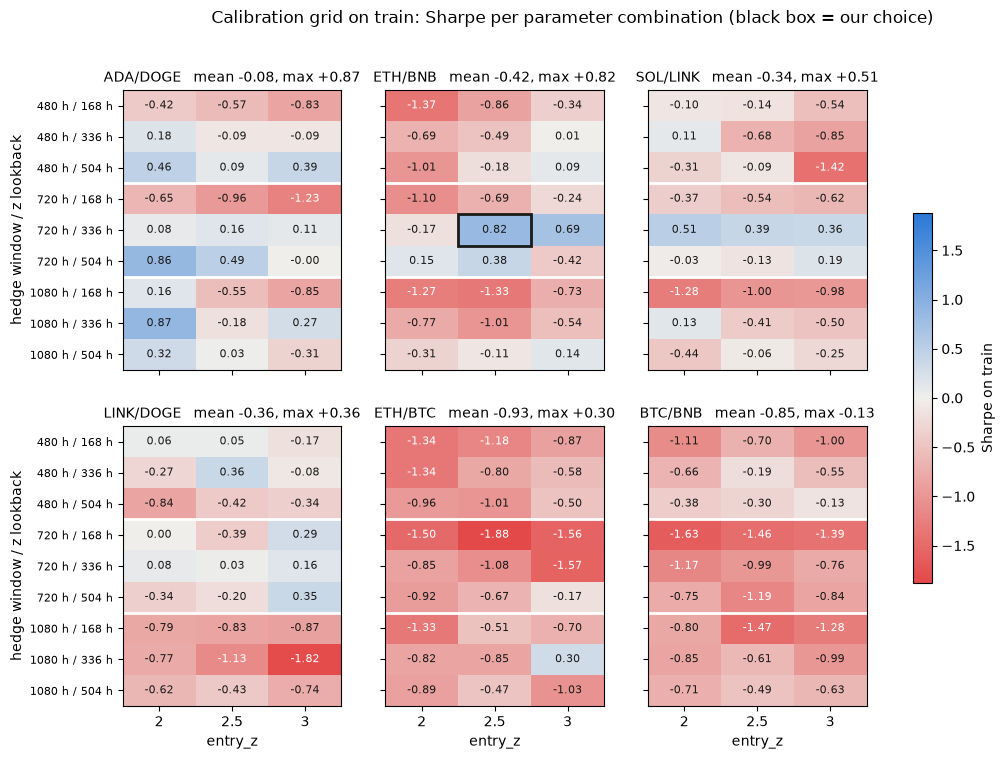

In [21]:
# Sharpe heatmap per pair: red = loses money, grey = 0, blue = makes money.
# A real effect shows up as a blue PLATEAU (a cell and its neighbours), not a single blue cell.
cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
vmax = grid["sharpe"].abs().max()
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
order = grid.groupby("pair")["sharpe"].max().sort_values(ascending=False).index
chosen = "/".join(cfg["pair"])

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)
for ax, pair in zip(axes.flat, order):
    t = grid[grid.pair == pair].pivot_table(index=["hedge_window", "lookback"], columns="entry_z", values="sharpe")
    im = ax.imshow(t.values, cmap=cmap, norm=norm, aspect="auto")
    for (i, j), v in np.ndenumerate(t.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 * vmax else "#1a1a19")
    for i in (2.5, 5.5):                                  # separate the three hedge windows
        ax.axhline(i, color="white", lw=2)
    if pair == chosen:
        i = list(t.index).index((cfg["hedge_window"], cfg["zscore_lookback"]))
        j = list(t.columns).index(cfg["entry_z"])
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="#1a1a19", lw=2))
    ax.set_title(f"{pair}   mean {t.values.mean():+.2f}, max {t.values.max():+.2f}", fontsize=10)
    ax.set_xticks(range(len(t.columns)), [f"{c:g}" for c in t.columns])
    ax.set_yticks(range(len(t.index)), [f"{hw} h / {lb} h" for hw, lb in t.index], fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("entry_z")
for ax in axes[:, 0]:
    ax.set_ylabel("hedge window / z lookback")
fig.colorbar(im, ax=axes, shrink=0.6, label="Sharpe on train")
fig.suptitle("Calibration grid on train: Sharpe per parameter combination (black box = our choice)")
plt.show()

**What we see:**
- Most combinations lose money (red), for every pair. Short lookbacks (168 h) are bad almost everywhere, because
  the spread then hardly moves away from its own short-term mean and costs dominate.
- **ETH/BNB**: the best cell (720 h / 336 h / 2.5, black box) has Sharpe 0.82, and its neighbours along entry_z and
  lookback are positive too (0.69, 0.38). But change the hedge window to 480 h or 1080 h and it turns clearly
  negative. So it is a narrow ridge, not a broad plateau.
- **ADA/DOGE** looks at least as good on Sharpe alone: the highest mean (−0.08) and the highest max (0.87), with
  more positive cells. But its good cells are scattered, and its best cell has a max drawdown of −26% (ETH/BNB: −17%).

**The good cells are isolated** for every pair. That is a warning sign: the best cell of 162 tries is partly luck
(overfitting), so we expect the test result to be weaker than the train result.

**Choice:** ETH/BNB, hedge_window = 720, zscore_lookback = 336, entry_z = 2.5 (saved in `config.yaml`).
The grid alone does not make ETH/BNB the winner. We chose it for the clearer economic link (native coins of the
two largest smart-contract platforms) and the lower drawdown.

In [22]:
variants = {"no stops": dict(stop_z=99, time_stop_hours=10**6),
            "stop loss only": dict(time_stop_hours=10**6),
            "time stop only": dict(stop_z=99),
            "both (our choice)": {}}
pd.DataFrame({name: strategy.backtest(prices, funding, dict(cfg, **v))["metrics"] for name, v in variants.items()}
             ).loc[["sharpe", "total_return", "max_drawdown", "n_trades", "win_rate"]]

,no stops,stop loss only,time stop only,both (our choice)
sharpe,0.686,1.103,0.379,0.824
total_return,0.438,0.681,0.181,0.443
max_drawdown,-0.269,-0.159,-0.280,-0.170
n_trades,83.000,101.000,85.000,101.000
win_rate,0.627,0.564,0.647,0.574


The **stop loss** at |z| > 3.5 is the rule that matters: it cuts the max drawdown from about −27% to about −16%
and even raises the Sharpe.

The **time stop** of 168 h (one week) does **not** help on train: Sharpe 1.10 without it vs 0.82 with it.
We kept it as a safety rule (no trade can block the capital for weeks). Looking back, a strict train-data
decision would have dropped it. We did **not** change it after seeing the test result, so the test stays clean.

## 5. Results on train (in-sample)

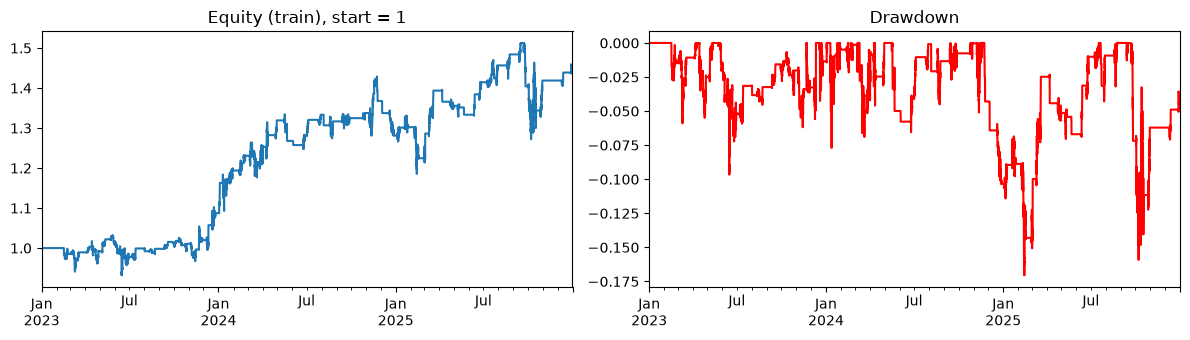

exit_reason
take_profit    53
stop_loss      31
time_stop      16
end_of_data     1


,train
total_return,0.443
annual_return,0.130
sharpe,0.824
max_drawdown,-0.170
n_trades,101.000
win_rate,0.574
avg_trade_return,0.004
avg_hours_in_trade,71.198
time_in_market,0.273
sum_gross,0.550


In [23]:
def show(res):
    b = res["bars"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    b["equity"].plot(ax=ax[0], title=f"Equity ({res['period']}), start = 1")
    (b["equity"] / b["equity"].cummax().clip(lower=1) - 1).plot(ax=ax[1], title="Drawdown", color="r")
    plt.tight_layout(); plt.show()
    print(res["trades"]["exit_reason"].value_counts().to_string())
    return pd.Series(res["metrics"]).to_frame(res["period"])

show(res_train)

In [24]:
res_train["trades"].head(10)   # first trades: when, which direction, z at entry/exit, return, why closed

,entry,exit,direction,hours,entry_z,exit_z,return,exit_reason
0,2023-02-15 18:00:00+00:00,2023-02-15 20:00:00+00:00,short spread,2,2.511,3.799,-0.017,stop_loss
1,2023-02-17 00:00:00+00:00,2023-02-24 00:00:00+00:00,short spread,168,2.610,0.594,0.003,time_stop
2,2023-03-03 01:00:00+00:00,2023-03-09 20:00:00+00:00,long spread,163,-2.731,-4.396,-0.041,stop_loss
3,2023-03-10 14:00:00+00:00,2023-03-12 17:00:00+00:00,long spread,51,-2.864,0.588,0.031,take_profit
4,2023-03-16 14:00:00+00:00,2023-03-18 12:00:00+00:00,long spread,46,-2.584,0.123,0.015,take_profit
5,2023-04-05 00:00:00+00:00,2023-04-09 10:00:00+00:00,short spread,106,2.721,-0.052,0.014,take_profit
6,2023-04-14 12:00:00+00:00,2023-04-17 02:00:00+00:00,short spread,62,2.909,-0.066,-0.008,take_profit
7,2023-04-21 07:00:00+00:00,2023-04-28 07:00:00+00:00,long spread,168,-2.616,-0.268,-0.003,time_stop
8,2023-05-05 16:00:00+00:00,2023-05-12 04:00:00+00:00,short spread,156,2.629,-0.090,0.030,take_profit
9,2023-05-23 04:00:00+00:00,2023-05-24 13:00:00+00:00,short spread,33,2.742,-0.180,0.008,take_profit


### Trading frequency and holding time

In [25]:
def frequency(res):
    t, months = res["trades"], len(res["bars"]) / 730          # 730 hours ≈ 1 month
    return pd.Series({"trades per month": len(t) / months,
                      "median hours in trade": t["hours"].median(),
                      "mean hours in trade": t["hours"].mean(),
                      "share of time in a trade": res["metrics"]["time_in_market"]})

frequency(res_train)

trades per month            2.803
median hours in trade      58.000
mean hours in trade        71.198
share of time in a trade    0.273
dtype: float64

About **3 trades per month**, each held for **2–3 days** on average (one week at most because of the time stop).
We are in a trade about a quarter of the time. This is a short-term swing strategy on hourly data, not high-frequency trading.

### How the trades ended

In [26]:
def by_exit(res):
    t = res["trades"]
    return t.groupby("exit_reason")["return"].agg(
        trades="count", avg_return="mean", total_return="sum", win_rate=lambda r: (r > 0).mean())

by_exit(res_train)

,trades,avg_return,total_return,win_rate
exit_reason,,,,
end_of_data,1,0.003,0.003,1.000
stop_loss,31,-0.018,-0.559,0.000
take_profit,53,0.020,1.038,0.925
time_stop,16,-0.005,-0.086,0.500


Take-profit trades make the money (+2.0% on average, 92% win). Stop losses cost −1.8% on average. Time stops are
about break-even. Average win +2.0% vs average loss −1.8%, with a 57% win rate overall.

### Trade walkthrough: best and worst trade on train

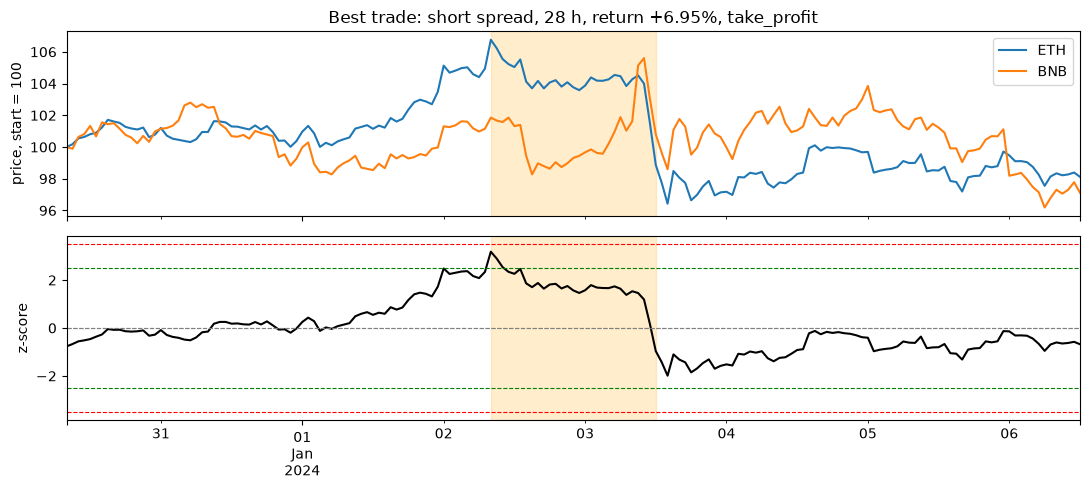

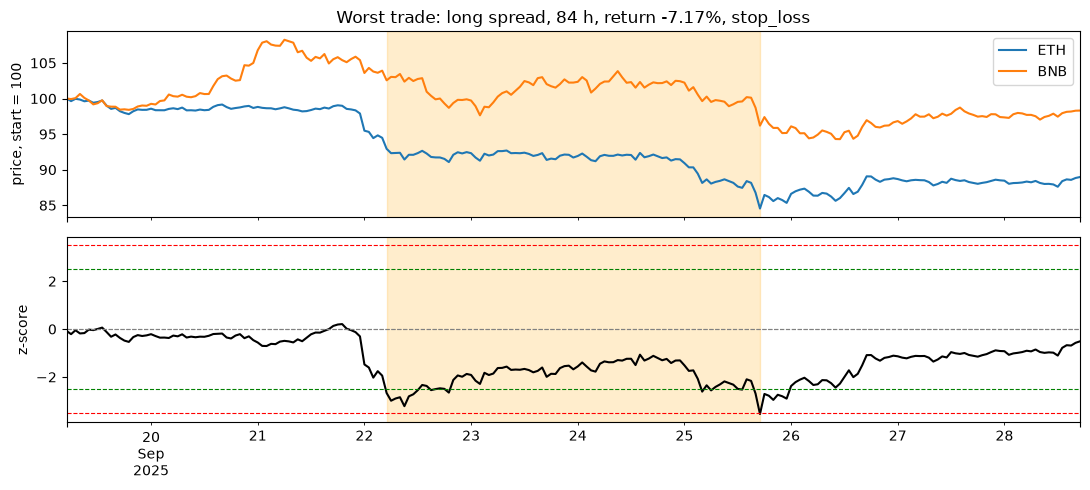

In [27]:
def plot_trade(res, i, title):
    t = res["trades"].iloc[i]
    b = res["bars"].loc[t["entry"] - pd.Timedelta("72h"): t["exit"] + pd.Timedelta("72h")]
    fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    (b[["price_a", "price_b"]] / b[["price_a", "price_b"]].iloc[0] * 100).set_axis(cfg["pair"], axis=1).plot(
        ax=ax[0], title=f"{title}: {t['direction']}, {t['hours']} h, return {t['return']:+.2%}, {t['exit_reason']}")
    b["z"].plot(ax=ax[1], color="k", label="z")
    for level, color in [(cfg["entry_z"], "g"), (cfg["stop_z"], "r"), (0, "grey")]:
        ax[1].axhline(level, color=color, ls="--", lw=0.8); ax[1].axhline(-level, color=color, ls="--", lw=0.8)
    for a in ax:
        a.axvspan(t["entry"], t["exit"], color="orange", alpha=0.2)
    ax[0].set_ylabel("price, start = 100"); ax[1].set_ylabel("z-score")
    plt.tight_layout(); plt.show()

trades = res_train["trades"]
plot_trade(res_train, trades["return"].idxmax(), "Best trade")
plot_trade(res_train, trades["return"].idxmin(), "Worst trade")

- **Best trade** (Jan 2024): z jumped above +3.2, so ETH was very expensive compared with BNB. We shorted the spread
  (short ETH, long BNB). Within 28 hours ETH fell 7.4% and BNB only 1.0%, z fell back through 0: take profit, **+7.0%**.
- **Worst trade** (Sep 2025): z fell below −2.7, so we went long the spread (long ETH, short BNB). Instead of coming back,
  the spread only recovered halfway (z about −1.2), never reached 0, and on 25 Sep ETH fell again and z passed −3.5:
  stop loss after 84 hours, **−7.2%**. ETH fell 9.0% and BNB 6.2%.

**Important observation:** in both trades the rolling beta at entry was very low (0.10 and 0.16), so about 90% of the
capital was in ETH and only 10% in BNB. These two trades were mostly **bets on ETH's direction**, not on the spread.
About 1 in 5 trades is entered with beta < 0.5. Those trades are much riskier (std of trade return 3.5% vs 2.0%).
They happened to make money on average, so filtering them out would make the strategy cleaner, but not necessarily more profitable.

## 6. Results on test (out-of-sample, run once)
Same code, same parameters. The rolling beta and z-score warm up on the end of the train period
(they only look backwards), so no future data is used.

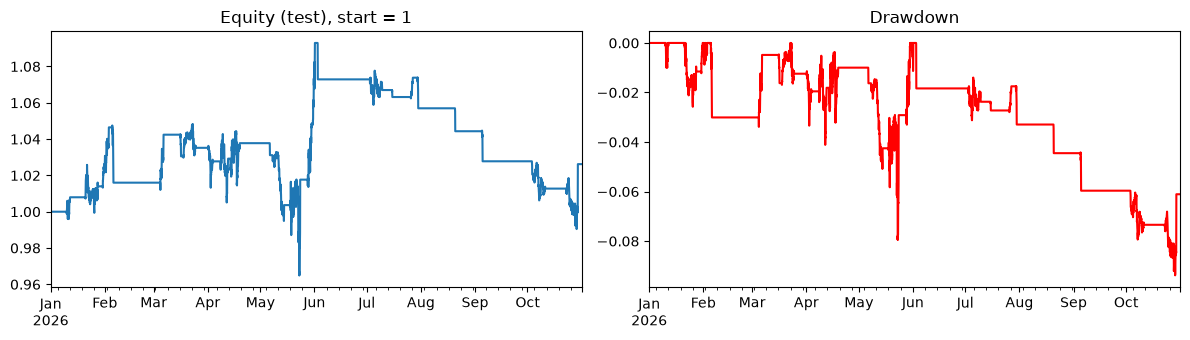

exit_reason
take_profit    13
stop_loss       9
time_stop       4


,test
total_return,0.026
annual_return,0.032
sharpe,0.326
max_drawdown,-0.094
n_trades,26.000
win_rate,0.500
avg_trade_return,0.001
avg_hours_in_trade,67.615
time_in_market,0.241
sum_gross,0.069


In [28]:
res_test = strategy.backtest(prices, funding, cfg, "test")
show(res_test)

In [14]:
display(frequency(res_test).to_frame("test"), by_exit(res_test))
res_test["trades"]   # all 26 test trades

,test
trades per month,2.601
median hours in trade,45.500
mean hours in trade,67.615
share of time in a trade,0.241


,trades,avg_return,total_return,win_rate
exit_reason,,,,
stop_loss,9,-0.013,-0.119,0.000
take_profit,13,0.012,0.152,0.846
time_stop,4,-0.001,-0.003,0.500


,entry,exit,direction,hours,entry_z,exit_z,return,exit_reason
0,2026-01-10 03:00:00+00:00,2026-01-12 02:00:00+00:00,long spread,47,-3.418,0.059,0.008,take_profit
1,2026-01-20 22:00:00+00:00,2026-01-27 22:00:00+00:00,long spread,168,-2.906,-0.361,0.006,time_stop
2,2026-01-30 20:00:00+00:00,2026-01-31 13:00:00+00:00,long spread,17,-2.601,0.345,0.012,take_profit
3,2026-01-31 22:00:00+00:00,2026-02-03 07:00:00+00:00,short spread,57,2.695,-0.165,0.020,take_profit
4,2026-02-05 05:00:00+00:00,2026-02-05 20:00:00+00:00,short spread,15,3.478,4.084,-0.029,stop_loss
5,2026-03-04 18:00:00+00:00,2026-03-06 14:00:00+00:00,short spread,44,2.694,-0.473,0.026,take_profit
6,2026-03-16 05:00:00+00:00,2026-03-16 14:00:00+00:00,short spread,9,2.714,3.567,-0.011,stop_loss
7,2026-03-18 00:00:00+00:00,2026-03-25 00:00:00+00:00,short spread,168,2.500,0.652,0.005,time_stop
8,2026-04-01 06:00:00+00:00,2026-04-04 02:00:00+00:00,short spread,68,3.401,-0.048,-0.007,take_profit
9,2026-04-08 06:00:00+00:00,2026-04-12 14:00:00+00:00,short spread,104,2.600,-0.062,0.001,take_profit


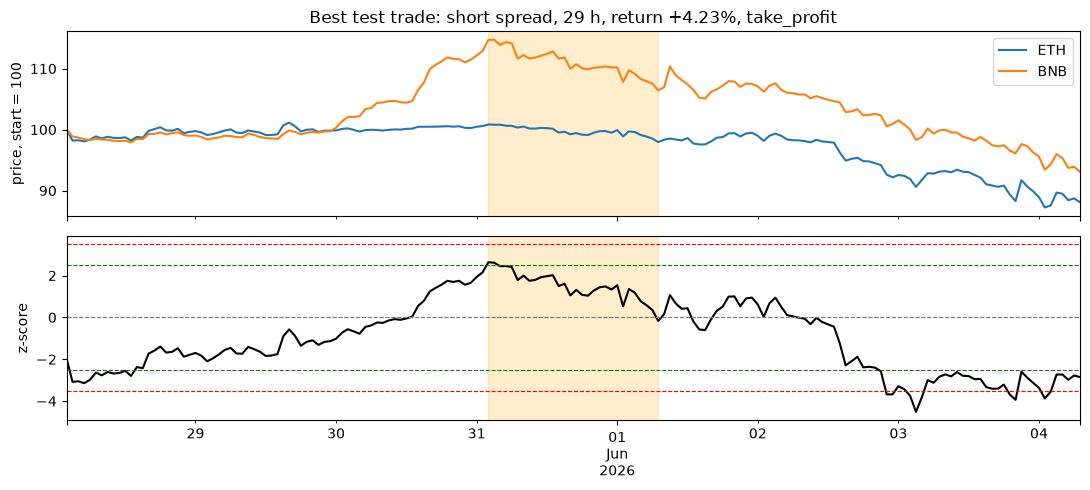

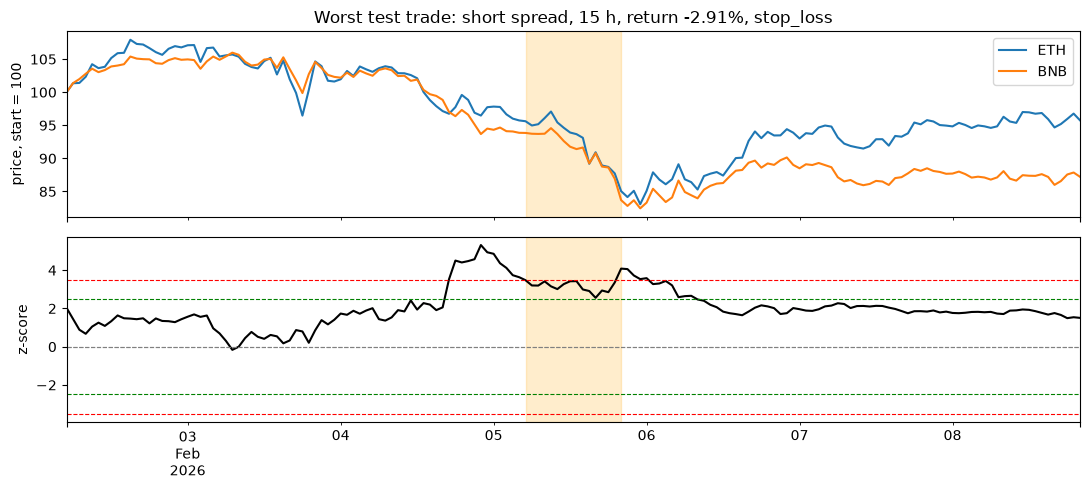

In [15]:
t = res_test["trades"]
plot_trade(res_test, t["return"].idxmax(), "Best test trade")
plot_trade(res_test, t["return"].idxmin(), "Worst test trade")

**What the test trades show:**
- The equity peaked at about **+9% on 1 June 2026**, then gave most of it back: 8 of the last 10 trades were stop
  losses or time stops.
- All 9 stop losses came **within 15 hours of entry** (5 within 3 hours), mostly from entries just above 2.5.
  z often jumps by more than 1 in a few hours, so a strong move goes straight through the narrow band between entry (2.5) and stop (3.5).
- Two take-profit trades **lost money** (Apr and May). The z-score came back to 0 partly because the rolling mean moved
  toward the spread, not because the spread itself came back. The z-score is a moving target.

In [16]:
# Robustness: what if costs are higher, or without funding?
checks = {}
for period in ["train", "test"]:
    checks[(period, "base")] = strategy.backtest(prices, funding, cfg, period)["metrics"]
    checks[(period, "fees x2")] = strategy.backtest(prices, funding, dict(cfg, fee=2 * cfg["fee"]), period)["metrics"]
    checks[(period, "no funding")] = strategy.backtest(prices, None, cfg, period)["metrics"]
pd.DataFrame(checks).loc[["sharpe", "total_return", "max_drawdown", "n_trades", "sum_gross", "sum_costs", "sum_funding"]]

train                      test                   
                base fees x2 no funding   base fees x2 no funding
sharpe         0.824   0.620      0.827  0.326   0.056      0.340
total_return   0.443   0.304      0.445  0.026  -0.000      0.028
max_drawdown  -0.170  -0.177     -0.171 -0.094  -0.102     -0.094
n_trades     101.000 101.000    101.000 26.000  26.000     26.000
sum_gross      0.550   0.550      0.550  0.069   0.069      0.069
sum_costs     -0.141  -0.242     -0.141 -0.036  -0.062     -0.036
sum_funding   -0.001  -0.001      0.000 -0.001  -0.001      0.000

## 7. Challenges

1. **No pair is truly cointegrated.** Not one of 66 pairs survives the multiple-testing correction, so the basic
   assumption of pairs trading only holds loosely and locally. We used rolling estimates to cope with this.
2. **Fake pairs.** The two "best" pairs contained LTC, which is stationary on its own. We only caught this by testing each leg alone.
3. **Overfitting.** We tried 162 parameter combinations. The chosen one is an isolated peak, so the test Sharpe dropped from 0.82 to 0.33.
4. **Costs.** A round trip costs ~0.14%. Costs ate about a quarter of the gross profit on train and half on test.
5. **Unstable hedge ratio.** The rolling beta ranges from −0.5 to 4.1. When it is near 0, almost all capital sits in
   ETH, and the trade is a directional ETH bet instead of a hedged spread trade (see our best and worst trade).
6. **Moving target.** The z-score depends on a rolling mean, so it can return to 0 without the trade making money.
7. **Timing without lookahead.** Candle labels (open time vs close price) and funding timestamps had to be handled
   carefully, so that a position never earns a price move or pays a funding payment from before it was opened.

## 8. Conclusions

- **Train:** Sharpe ≈ 0.8, +44% over 3 years, max drawdown ≈ −17%, ~100 trades.
- **Test:** Sharpe ≈ 0.3, +2.6% over 10 months, max drawdown ≈ −9%, 26 trades. The strategy is still slightly
  positive, but much weaker than on train. That is what we expected, because the chosen parameters were an isolated peak.
- **Costs matter a lot:** fees and slippage eat about a quarter of the gross profit on train and half of it on test.
  With double fees the test result is zero.
- **Funding hardly matters:** being long one perpetual and short another, the payments mostly cancel out.
- **Main lesson:** crypto pairs are not reliably cointegrated (no pair survives the multiple-testing correction),
  so the edge is small and fragile.

**What we would do next:** test the strategy on many pairs at once (a portfolio, more trades, more reliable statistics),
use walk-forward re-calibration, and use maker orders to cut fees.